# Adult Census Income Classification
## End-to-End Pipeline: Boosting Algorithms, Optuna Tuning, and Stacking Ensembles

---

### Project Overview
The objective of this project is to build an end-to-end machine learning classification system to predict whether an individual's annual income exceeds $50,000 using demographic, education, and employment data from the 1994 U.S. Census Bureau database (UCI Adult Dataset).

**Target Variable (`income`):**
- `0` (`<=50K`): Annual income less than or equal to $50,000.
- `1` (`>50K`): Annual income strictly greater than $50,000.

### Dataset Description
- **Source**: UCI Machine Learning Repository
- **Size**: 32,561 rows and 15 raw features
- **Continuous Features**: `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`
- **Categorical Features**: `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`
- **Target**: `income`

### Pipeline Roadmap
1. **Exploratory Data Analysis (EDA)**: Read-only audit of missing values, class distributions, skewness, and feature correlations.
2. **Data Partitioning**: Stratified Train-Test Split (80% development, 20% hold-out test) prior to any transformations to strictly prevent data leakage.
3. **Feature Engineering & Preprocessing**: Constructing isolated pipelines per algorithm (One-Hot Encoding for XGBoost, native categorical handling for LightGBM and CatBoost, standard scaling for linear estimators).
4. **Hyperparameter Optimization**: Systematic Bayesian tuning using Optuna with Stratified K-Fold Cross-Validation.
5. **Ensemble Methods**: Evaluation and comparison of Voting Classifiers, Blending, and Out-of-Fold (OOF) Stacking with a Logistic Regression meta-learner.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import pandas as pd

# Correct URL to the Census Income dataset on UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# The dataset does not have a header, so we should define the columns
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=columns, skipinitialspace=True)

print(f"Data Shape: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
df.head()

Data Shape: 32,561 Rows | 15 Columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# 1. Remove extra whitespace from text values (to ensure detection of '?' or ' ?')
df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)

# 2. Replace any '?' marker with a genuine missing value (NaN)
df = df.replace("?", np.nan)

# 3. Drop the education and fnlwgt columns
df = df.drop(columns=["education", "fnlwgt"], errors="ignore")

# 4. Check and count genuine missing values in each column
missing_summary = pd.DataFrame(
    {
        "Missing Count": df.isnull().sum(),
        "Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

# Display only columns containing missing values
print(f"Data Shape After Drop: {df.shape}")
print("\n--- Missing Values Breakdown ---")
print(missing_summary[missing_summary["Missing Count"] > 0])

Data Shape After Drop: (32561, 13)

--- Missing Values Breakdown ---
                Missing Count  Percentage (%)
workclass                1836            5.64
occupation               1843            5.66
native-country            583            1.79


In [4]:
for i in df.columns:
  print(df[i].value_counts())

age
36    898
31    888
34    886
23    877
35    876
     ... 
83      6
88      3
85      3
86      1
87      1
Name: count, Length: 73, dtype: int64
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education-num
9     10501
10     7291
13     5355
14     1723
11     1382
7      1175
12     1067
6       933
4       646
15      576
5       514
8       433
16      413
3       333
2       168
1        51
Name: count, dtype: int64
marital-status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   education-num   32561 non-null  int64 
 3   marital-status  32561 non-null  object
 4   occupation      30718 non-null  object
 5   relationship    32561 non-null  object
 6   race            32561 non-null  object
 7   sex             32561 non-null  object
 8   capital-gain    32561 non-null  int64 
 9   capital-loss    32561 non-null  int64 
 10  hours-per-week  32561 non-null  int64 
 11  native-country  31978 non-null  object
 12  income          32561 non-null  object
dtypes: int64(5), object(8)
memory usage: 3.2+ MB


In [6]:
df.describe()

,age,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,1077.648844,87.303830,40.437456
std,13.640433,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.000000,0.000000,0.000000,1.000000
25%,28.000000,9.000000,0.000000,0.000000,40.000000
50%,37.000000,10.000000,0.000000,0.000000,40.000000
75%,48.000000,12.000000,0.000000,0.000000,45.000000
max,90.000000,16.000000,99999.000000,4356.000000,99.000000


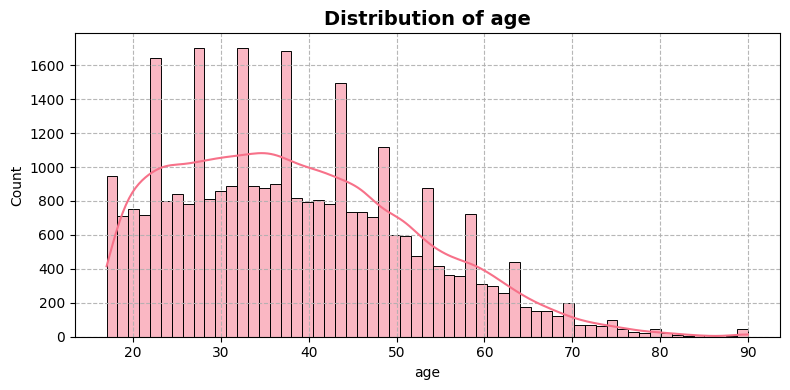

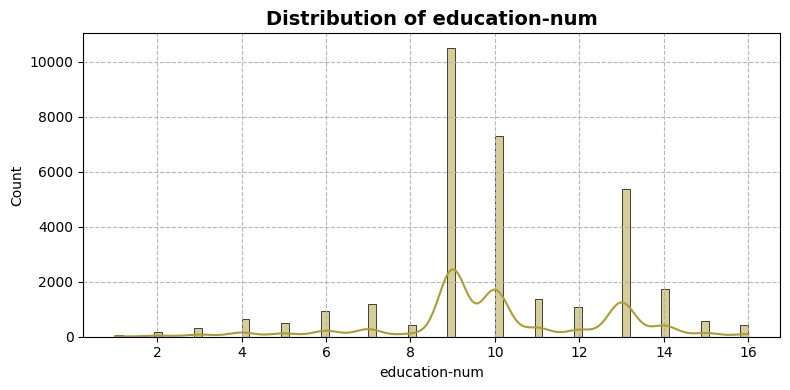

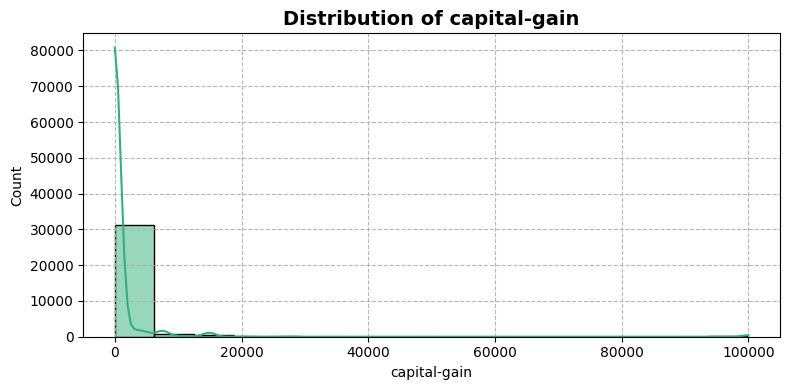

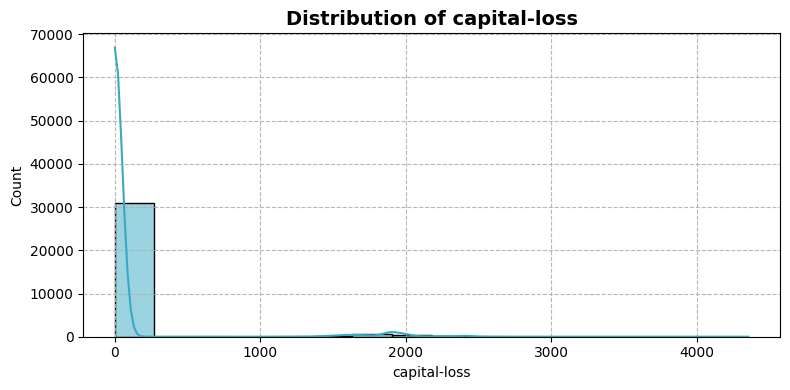

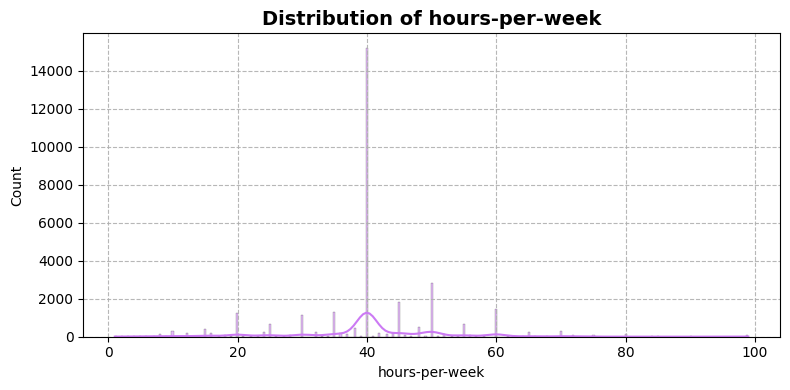

In [7]:
palette = sns.color_palette("husl" , len(df.select_dtypes(include="number").columns))

for idx , col in enumerate(df.select_dtypes(include="number").columns):
  plt.figure(figsize=(8 , 4))
  sns.histplot(data=df , x=col , color=palette[idx] , edgecolor="black" , kde=True)
  plt.title(f"Distribution of {col}" , fontsize=14 , fontweight="bold")
  plt.grid(True , linestyle='--' , alpha=0.9)
  plt.tight_layout()
  plt.show()

In [8]:
# 1. Create a completely separate copy for Exploratory Data Analysis (EDA)
df_eda = df.copy()

# 2. Convert the target variable (income_bracket) into binary values (0 and 1)
df_eda["income"] = (
    df_eda["income"]
    .astype(str)
    .str.rstrip(".")
    .map({"<=50K": 0, ">50K": 1})
)

# 3. Encode categorical (Object) columns into numeric values while preserving NaN
cat_columns = df_eda.select_dtypes(include=["object"]).columns

for col in cat_columns:
    cat_series = df_eda[col].astype("category")
    # Replace -1 (automatically assigned by pandas to NaN) with np.nan to avoid distorting correlation calculations
    df_eda[col] = cat_series.cat.codes.replace(-1, np.nan)

# 4. Ensure that all columns are fully numeric
print("EDA Data Shape:", df_eda.shape)
print("\nColumn Data Types After Encoding:")
print(df_eda.dtypes)
df_eda.head()

EDA Data Shape: (32561, 13)

Column Data Types After Encoding:
age                 int64
workclass         float64
education-num       int64
marital-status       int8
occupation        float64
relationship         int8
race                 int8
sex                  int8
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country    float64
income              int64
dtype: object


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,6.0,13,4,0.0,1,4,1,2174,0,40,38.0,0
1,50,5.0,13,2,3.0,0,4,1,0,0,13,38.0,0
2,38,3.0,9,0,5.0,1,4,1,0,0,40,38.0,0
3,53,3.0,7,2,5.0,0,2,1,0,0,40,38.0,0
4,28,3.0,13,2,9.0,5,2,0,0,0,40,4.0,0


/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


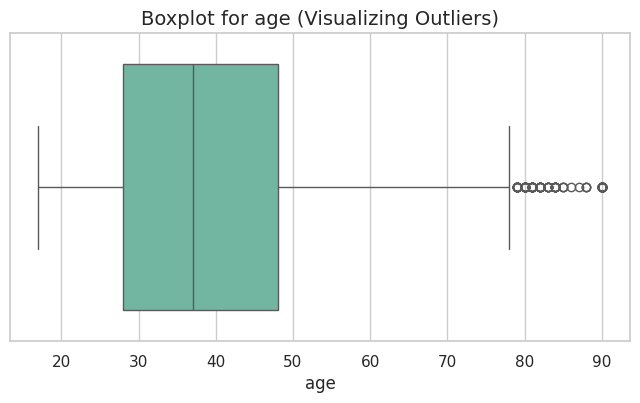

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


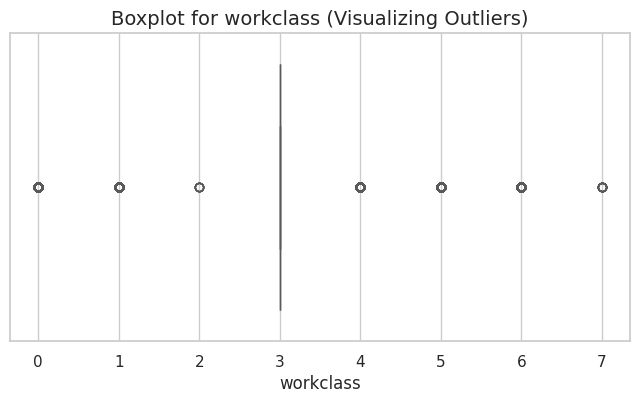

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


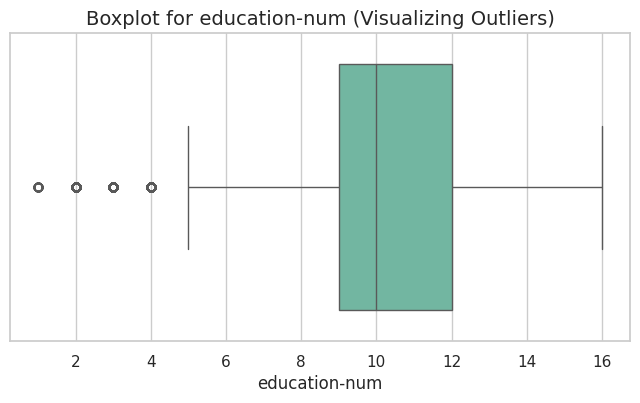

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


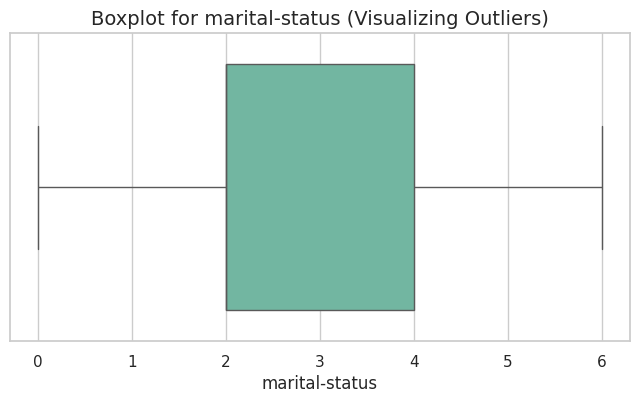

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


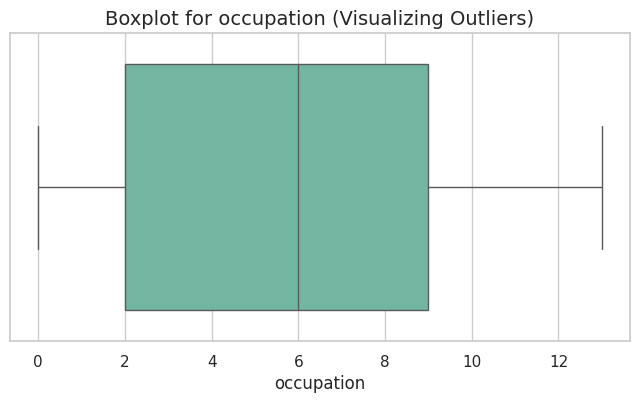

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


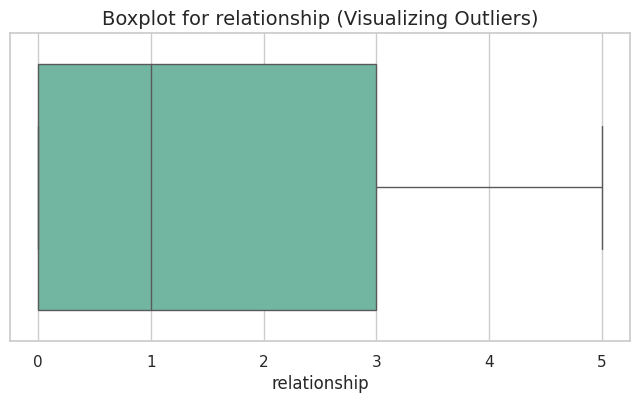

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


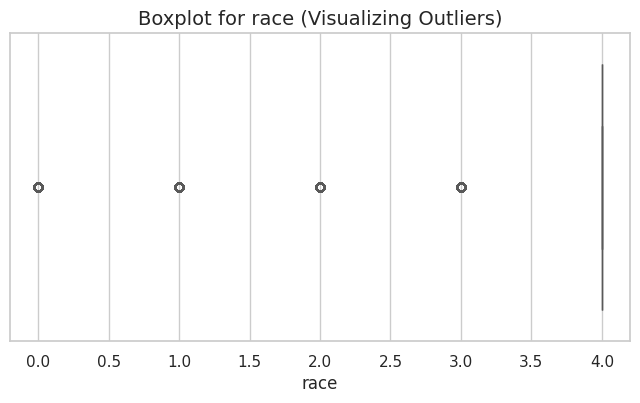

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


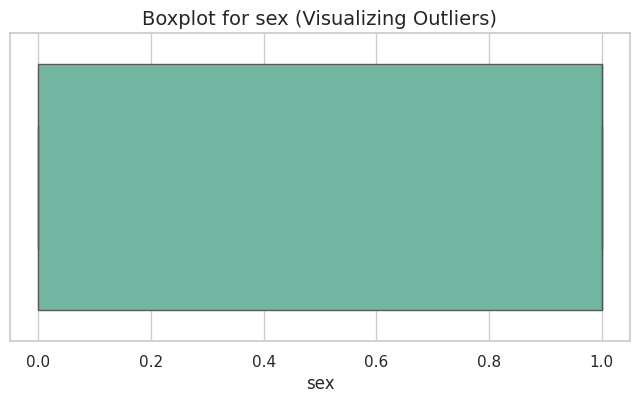

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


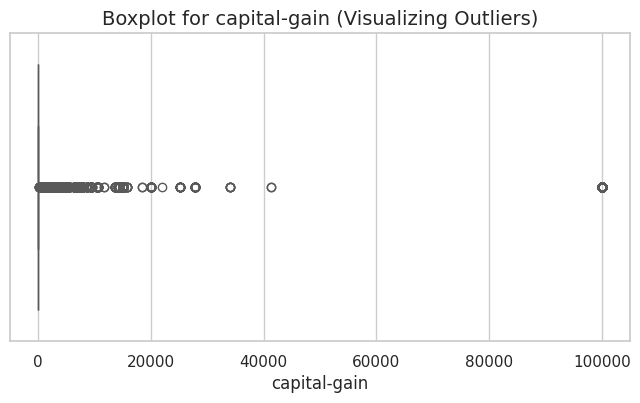

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


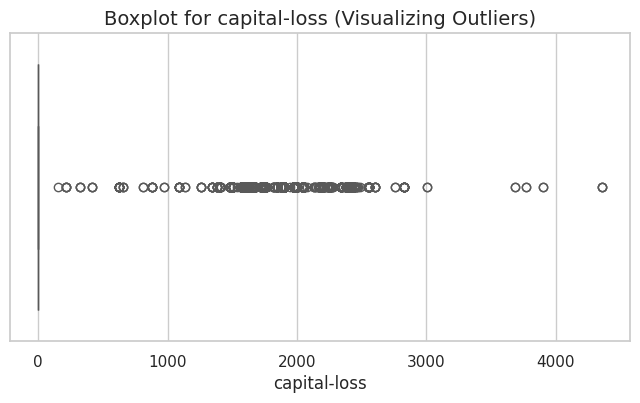

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


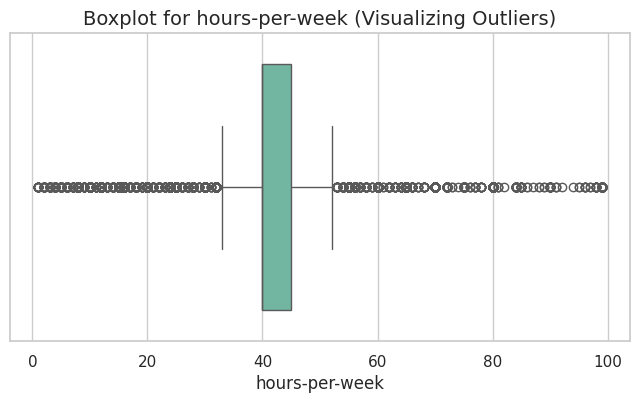

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


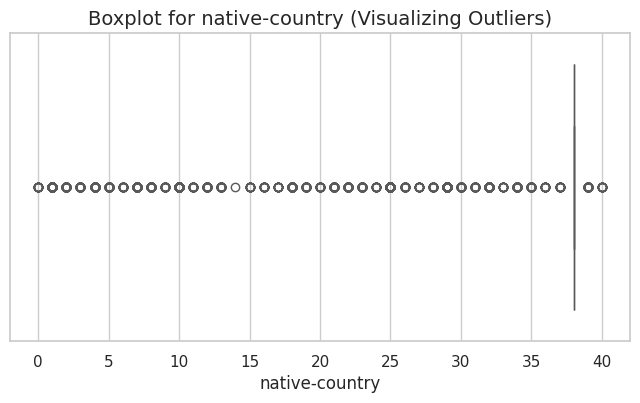

/tmp/ipykernel_2339/1810257956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda , x=col , palette="Set2")


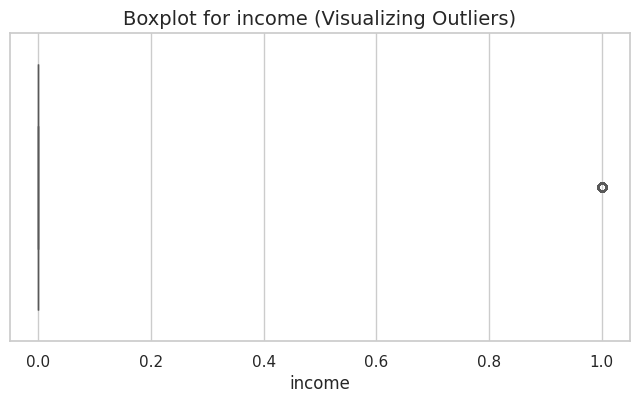

In [ ]:
for col in df_eda.columns:
  plt.figure(figsize=(8 , 4))
  sns.boxplot(data=df_eda , x=col , palette="Set2")
  plt.title(f"Boxplot for {col} (Visualizing Outliers)" , fontsize=14)
  plt.show()

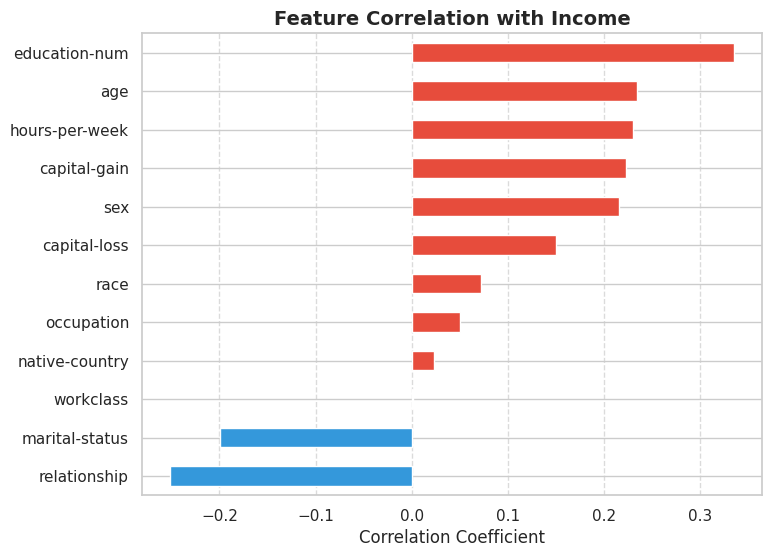

In [ ]:
income_corr = df_eda.corr()['income'].drop('income').sort_values(ascending=True)

plt.figure(figsize=(8, 6))
income_corr.plot(kind='barh', color=income_corr.map(lambda x: '#e74c3c' if x > 0 else '#3498db'))
plt.title("Feature Correlation with Income", fontsize=14, fontweight='bold')
plt.xlabel("Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Exploratory Data Analysis: Key Findings and Engineering Decisions

---

### 1. Data Cleaning and Attribute Selection
- **Missing Value Standardization**: Missing entries encoded as `?` were converted to standard `np.nan` across all columns[cite: 1].
- **Redundant Feature Removal**: `education` was dropped due to perfect collinearity with `education-num`, which provides the equivalent ordinal numerical scale[cite: 1].
- **Noise Reduction**: `fnlwgt` (final sampling weight) was removed because it reflects census survey weights rather than individual predictive behavioral characteristics[cite: 1].

### 2. Missing Values Audit
- Missing values are strictly confined to three categorical attributes:
  - `occupation`: 1,843 missing values (5.66%)[cite: 1]
  - `workclass`: 1,836 missing values (5.64%)[cite: 1]
  - `native-country`: 583 missing values (1.79%)[cite: 1]
- All continuous numerical features contain zero missing values[cite: 1].
- **Decision**: Missing categories will be handled via frequent-value imputation inside model-specific pipelines strictly after the train-test split to avoid data leakage.

### 3. Class Imbalance Assessment
- **Class Distribution**:
  - `<=50K`: 24,720 samples (75.92%)[cite: 1]
  - `>50K`: 7,841 samples (24.08%)[cite: 1]
- **Imbalance Ratio**: Approximately 3.15 : 1.
- **Decision**:
  - Accuracy will not be used as the primary metric; model selection will prioritize **ROC-AUC**, PR-AUC, and F1-Score.
  - Stratification will be enforced across all splits (`StratifiedKFold`).
  - The `scale_pos_weight` parameter will be configured in boosting models to adjust for class proportions.

### 4. Continuous Feature Distributions and Outliers
- **Capital Features**: `capital-gain` (91.6% zero values) and `capital-loss` (95.3% zero values) display severe positive skewness, with outliers extending up to 99,999[cite: 1].
- **Working Hours**: `hours-per-week` peaks around 40 hours (mean: 40.43, standard deviation: 12.35), with tails reflecting part-time and overtime employment[cite: 1].
- **Age**: Moderately right-skewed across ages 17 to 90, with a median of 37 years[cite: 1].
- **Decision**: Tree-based gradient boosting models are invariant to monotonic transformations and naturally robust to isolated outliers. Outliers will not be arbitrarily removed; instead, derived binary indicators will be engineered.

### 5. Correlation and Key Predictors
- **Numerical Features**: The strongest linear correlation with `income` is `education-num` (+0.34), followed by `age` (+0.23), `hours-per-week` (+0.23), and `capital-gain` (+0.22).
- **Categorical Patterns**:
  - `marital-status`: Married individuals (`Married-civ-spouse`) show a substantially higher probability of earning `>50K` compared to unmarried individuals[cite: 1].
  - `native-country`: High cardinality with 41 unique countries, heavily dominated by `United-States` (89.58%)[cite: 1].

### 6. Feature Engineering Blueprint
- **Capital Adjustments**:
  - `capital_net` = `capital-gain` - `capital-loss`
  - `has_capital_gain` = Binary flag (`capital-gain > 0`)
  - `has_capital_loss` = Binary flag (`capital-loss > 0`)
- **Categorical Consolidation**:
  - `native-country`: Group into binary categories (`United-States` vs. `Non-US`).
  - `marital-status`: Consolidate into high-level categories (`Married` vs. `Single_or_Divorced`).

---

### Next Phase: Stratified Partitioning and Model Pipelines
The dataset will now be divided into an 80% development set and a 20% hold-out test set using `StratifiedShuffleSplit`. Separate preprocessing pipelines will then be built for XGBoost, LightGBM, and CatBoost.

In [9]:
from sklearn.model_selection import train_test_split

# 1. Encode target variable 'income' to binary (0 and 1)
df['income'] = df['income'].astype(str).str.rstrip('.').map({'<=50K': 0, '>50K': 1})

# 2. Separate features (X) and target (y)
X = df.drop('income', axis=1)
y = df['income']

# 3. Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Reset index for clean indexing
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")
print(f"Train Class Distribution:\n{y_train.value_counts(normalize=True).round(4)}")

X_train shape: (26048, 12) | y_train shape: (26048,)
X_test shape:  (6513, 12)  | y_test shape:  (6513,)
Train Class Distribution:
income
0    0.7592
1    0.2408
Name: proportion, dtype: float64


In [10]:
# Identify categorical columns containing missing values
missing_cat_cols = ['workclass', 'occupation', 'native-country']

# Compute the mode for each column strictly from X_train to prevent data leakage
train_modes = {col: X_train[col].mode()[0] for col in missing_cat_cols}
print("Computed Modes from X_train:")
for col, mode_val in train_modes.items():
    print(f"  {col}: {mode_val}")

# Impute missing values in both X_train and X_test using the train modes
for col, mode_val in train_modes.items():
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)

# Verify no missing values remain
print(f"\nRemaining missing values in X_train: {X_train.isnull().sum().sum()}")
print(f"Remaining missing values in X_test:  {X_test.isnull().sum().sum()}")

Computed Modes from X_train:
  workclass: Private
  occupation: Prof-specialty
  native-country: United-States

Remaining missing values in X_train: 0
Remaining missing values in X_test:  0


In [11]:
# Define a helper function to apply feature engineering consistently
def engineer_features(data):
    df_feat = data.copy()

    # 1. Capital Net feature
    df_feat['capital_net'] = df_feat['capital-gain'] - df_feat['capital-loss']

    # 2. Binary indicators for capital investments
    df_feat['has_capital_gain'] = (df_feat['capital-gain'] > 0).astype(int)
    df_feat['has_capital_loss'] = (df_feat['capital-loss'] > 0).astype(int)

    # 3. Consolidate high-cardinality native-country (United-States vs Other)
    df_feat['is_native_us'] = (df_feat['native-country'] == 'United-States').astype(int)

    # 4. Consolidate marital-status into Married vs Unmarried
    married_categories = ['Married-civ-spouse', 'Married-AF-spouse']
    df_feat['is_married'] = df_feat['marital-status'].isin(married_categories).astype(int)

    # 5. Working hours indicator (Overtime vs Standard/Part-time)
    df_feat['is_overtime'] = (df_feat['hours-per-week'] > 40).astype(int)

    return df_feat

# Apply feature engineering to train and test sets
X_train = engineer_features(X_train)
X_test = engineer_features(X_test)

print("Engineered Features Added Successfully.")
print(f"Updated X_train shape: {X_train.shape}")
print(f"Updated X_test shape:  {X_test.shape}")
X_train[['capital_net', 'has_capital_gain', 'is_native_us', 'is_married', 'is_overtime']].head()

Engineered Features Added Successfully.
Updated X_train shape: (26048, 18)
Updated X_test shape:  (6513, 18)


,capital_net,has_capital_gain,is_native_us,is_married,is_overtime
0,0,0,1,1,1
1,0,0,1,0,1
2,0,0,1,0,0
3,6849,1,1,0,0
4,0,0,1,0,0


In [12]:
# Skewed features to transform using log1p (strictly non-negative)
skewed_cols = ['capital-gain', 'capital-loss']

for col in skewed_cols:
    # Create log-transformed columns (log1p = log(x + 1))
    X_train[f'{col}_log'] = np.log1p(X_train[col])
    X_test[f'{col}_log'] = np.log1p(X_test[col])

print("Log Transformation Applied to Skewed Continuous Features.")
print(f"Final X_train shape: {X_train.shape}")
print(f"Final X_test shape:  {X_test.shape}")
X_train[[f'{col}_log' for col in skewed_cols]].describe().T[['min', 'mean', '50%', 'max']].round(2)

Log Transformation Applied to Skewed Continuous Features.
Final X_train shape: (26048, 20)
Final X_test shape:  (6513, 20)


,min,mean,50%,max
capital-gain_log,0.0,0.73,0.0,11.51
capital-loss_log,0.0,0.35,0.0,8.38


In [13]:
# Verify dataset consistency and check data types
print("=== X_train Info Summary ===")
print(f"Total Features: {X_train.shape[1]}")
print(f"Numerical Features: {len(X_train.select_dtypes(include=['number']).columns)}")
print(f"Categorical Features: {len(X_train.select_dtypes(include=['object', 'category']).columns)}")
print(f"Categorical Columns List: {X_train.select_dtypes(include=['object', 'category']).columns.tolist()}")

# Ensure zero NaNs across train and test sets
assert X_train.isnull().sum().sum() == 0, "Warning: Null values detected in X_train!"
assert X_test.isnull().sum().sum() == 0, "Warning: Null values detected in X_test!"
print("\nIntegrity Check Passed: Zero missing values detected across both datasets.")

=== X_train Info Summary ===
Total Features: 20
Numerical Features: 13
Categorical Features: 7
Categorical Columns List: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Integrity Check Passed: Zero missing values detected across both datasets.


In [14]:
from sklearn.model_selection import StratifiedKFold

# 1. Clean feature names (replace '-' with '_' for LightGBM/XGBoost safety)
X_train.columns = X_train.columns.str.replace('-', '_')
X_test.columns = X_test.columns.str.replace('-', '_')

# 2. Explicitly define categorical and numerical feature lists
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")
print(f"Numerical Features ({len(num_cols)}): {num_cols}")

# 3. Calculate scale_pos_weight for handling class imbalance in boosting models
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"\nCalculated scale_pos_weight: {scale_pos_weight:.2f}")

# 4. Initialize unified Stratified 5-Fold CV scheme
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Stratified 5-Fold Cross-Validation Strategy Initialized.")

Categorical Features (7): ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numerical Features (13): ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_native_us', 'is_married', 'is_overtime', 'capital_gain_log', 'capital_loss_log']

Calculated scale_pos_weight: 3.15
Stratified 5-Fold Cross-Validation Strategy Initialized.


# Data Preprocessing and Feature Engineering Summary (Post-Split)

---

### 1. Data Partitioning and Leakage Prevention
- **Target Variable Encoding**: Converted `income` to binary integer format (`0` for `<=50K` and `1` for `>50K`).
- **Stratified Partitioning**: Split the dataset into an 80% training set and a 20% hold-out test set using `train_test_split` with `stratify=y` and `random_state=42`.
- **Integrity**: Indices were reset on both partitions, and all subsequent statistical parameters were learned strictly on the training set to prevent data leakage.

### 2. Missing Value Imputation
- Categorical attributes with missing values (`workclass`, `occupation`, and `native-country`) were audited.
- Imputed missing entries using the most frequent category (mode) computed exclusively from `X_train`, which was then propagated to both `X_train` and `X_test`.
- Post-imputation checks verified zero remaining null values across both sets.

### 3. Feature Extraction and Engineering
Engineered domain-specific features and binary indicators across both partitions:
- **Net Capital (`capital_net`)**: Quantifies overall investment returns calculated as `capital-gain` minus `capital-loss`.
- **Capital Activity Flags (`has_capital_gain`, `has_capital_loss`)**: Binary flags indicating whether an individual participated in asset gains or suffered losses.
- **Marital Status Consolidation (`is_married`)**: Aggregated civil and armed-forces spouse categories into a single binary indicator distinguishing married from unmarried individuals.
- **Geographic Simplification (`is_native_us`)**: Addressed high cardinality in `native-country` by creating a binary flag for U.S. origin versus foreign origin.
- **Labor Commitment Indicator (`is_overtime`)**: Identifies individuals working in excess of the standard 40-hour workweek (`hours-per-week > 40`).

### 4. Non-Linear Log Transformations
- Applied the `np.log1p` transformation to heavily right-skewed, strictly non-negative attributes:
  - `capital-gain_log` = `log(capital-gain + 1)`
  - `capital-loss_log` = `log(capital-loss + 1)`
- Constrained the transformation to these two features to preserve the linear and ordinal integrity of bounded features (`age`, `education-num`, and `hours-per-week`), while protecting derived features (`capital_net`) from negative values.

### 5. Production Sanitization and Evaluation Scheme
- **Feature Name Sanitization**: Substituted hyphens (`-`) with underscores (`_`) across all feature names to prevent serialization and parser issues in LightGBM and XGBoost.
- **Feature Group Segregation**: Separated features explicitly into `cat_cols` (raw categorical attributes for encoding) and `num_cols` (continuous attributes and binary indicators for scaling).
- **Imbalance Weight Configuration**: Derived `scale_pos_weight` directly from training label ratios (`~3.15`) to supply boosting loss functions with proper class weighting.
- **Unified Validation Strategy**: Initialized a 5-Fold `StratifiedKFold` scheme (`random_state=42`, `shuffle=True`) to be shared across all models, ensuring identical data folds for Optuna tuning, Blending, and Out-of-Fold (OOF) Stacking.


# Modeling Strategy: Two-Track Benchmarking and Optimization Framework

---

### 1. Architectural Strategy
To avoid arbitrary model comparison, the modeling phase is partitioned into two distinct, rigorous benchmark tracks. Each model or ensemble architecture is contained within its own dedicated pipeline, embedding a `ColumnTransformer` inside an **Optuna** objective function using 5-fold `StratifiedKFold` cross-validation. This setup guarantees complete isolation against data leakage during hyperparameter optimization.

---

### 2. Benchmark Track A: Advanced Ensemble Paradigms (Ensembles Battle)
The objective of Track A is to assess and compare the operational mechanisms and generalization properties of three distinct aggregation philosophies:

1. **Soft Voting Classifier**:
   - **Base Estimators**: Diversified algorithmic families (e.g., Logistic Regression, Gradient Boosting / Random Forest, and K-Nearest Neighbors / Support Vector Classifier).
   - **Mechanism**: Weighted or unweighted probability averaging across heterogeneous hypothesis spaces.
   - **Optimization Target**: Tuning estimator parameters and probability voting weights.

2. **Blending**:
   - **Base Estimators**: High-diversity combination (Random Forest, KNN, Logistic Regression).
   - **Meta-Learner**: Simple linear estimator (Logistic Regression).
   - **Mechanism**: Splitting the training set to train base models on a primary split and fitting the meta-learner on a hold-out blending subset.
   - **Focus Area**: Demonstrating the impact of data truncation on base model learning capacity.

3. **Stacking Classifier (OOF Meta-Learner)**:
   - **Base Estimators**: Identical combination to Blending (Random Forest, KNN, Logistic Regression).
   - **Meta-Learner**: Regularized Logistic Regression.
   - **Mechanism**: Generating Out-Of-Fold (OOF) cross-validated prediction matrices across all 5 training folds without data sacrifice.
   - **Comparative Benchmark**: Contrasting the stability and generalization gap of CV-driven Stacking against hold-out Blending.

---

### 3. Benchmark Track B: Gradient Boosting Frameworks (The Boosting Battle)
Track B evaluates the three leading gradient boosted decision tree implementations under identical validation conditions:

1. **XGBoost (Extreme Gradient Boosting)**:
   - **Preprocessing**: Explicit One-Hot Encoding via `ColumnTransformer` on categorical features; standard numeric pass-through.
   - **Tuning Focus**: Taylor expansion regularizers (`gamma`, `reg_lambda`), shrinkage (`learning_rate`), tree depth, and `scale_pos_weight`.

2. **LightGBM (Light Gradient Boosted Machine)**:
   - **Preprocessing**: Categorical ordinal or integer typing to leverage native histogram sorting and leaf-wise splitting.
   - **Tuning Focus**: GOSS parameters, `num_leaves`, `min_child_samples`, and memory-efficient tree growth constraints.

3. **CatBoost (Categorical Boosting)**:
   - **Preprocessing**: Raw string feature ingestion utilizing native `cat_features` handling without manual encoding.
   - **Tuning Focus**: Symmetric tree depth (`depth`), L2 regularization (`l2_leaf_reg`), random strength, and target-based categorical encodings.

- **Track B Comparison Dimensions**:
  - Training execution time (wall-clock latency across Optuna trials).
  - RAM consumption and model artifact size.
  - Resilience and handling efficiency of high-cardinality categorical variables.

---

### 4. Phase 3: Unified Leaderboard and Performance Audit
Following individual tuning and execution, all six finalized architectures will be evaluated simultaneously on the untouched 20% hold-out test set (`X_test`, `y_test`) across:
- **Threshold Metrics**: Accuracy, Precision, Recall, and F1-Score.
- **Imbalance-Aware Discriminative Metrics**: ROC-AUC Score and Precision-Recall AUC (PR-AUC).
- **Inference Diagnostics**: Latency per sample (milliseconds) and cross-validation to test score divergence (generalization gap).

In [17]:
!pip install optuna -q

import optuna
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# ---------------------------------------------------------
# 1. Feature Preprocessing Specifications
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessor for Linear & Distance models (Logistic Regression & KNN)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessor for Tree-based model (Gradient Boosting Machine)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# ---------------------------------------------------------
# 2. Optuna Objective Function for Voting Classifier (F1-Score)
# ---------------------------------------------------------


def objective_voting(trial):
  # --- A. Logistic Regression Hyperparameters ---
  lr_solver_type = trial.suggest_categorical(
      "lr_solver_type", ["lbfgs", "liblinear", "saga"]
  )
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_class_weight = trial.suggest_categorical(
      "lr_class_weight", [None, "balanced"]
  )

  if lr_solver_type == "liblinear":
    lr_penalty = trial.suggest_categorical("lr_penalty_liblinear", ["l1", "l2"])
    clf_lr = LogisticRegression(
        solver="liblinear",
        penalty=lr_penalty,
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  elif lr_solver_type == "lbfgs":
    clf_lr = LogisticRegression(
        solver="lbfgs",
        penalty="l2",
        C=lr_C,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )
  else:  # saga
    lr_penalty = trial.suggest_categorical(
        "lr_penalty_saga", ["l1", "l2", "elasticnet"]
    )
    lr_l1_ratio = (
        trial.suggest_float("lr_l1_ratio", 0.1, 0.9)
        if lr_penalty == "elasticnet"
        else None
    )
    clf_lr = LogisticRegression(
        solver="saga",
        penalty=lr_penalty,
        C=lr_C,
        l1_ratio=lr_l1_ratio,
        class_weight=lr_class_weight,
        max_iter=1000,
        random_state=42,
    )

  # --- B. Gradient Boosting Classifier Hyperparameters ---
  gbm_loss = trial.suggest_categorical("gbm_loss", ["log_loss", "exponential"])
  gbm_learning_rate = trial.suggest_float(
      "gbm_learning_rate", 0.01, 0.2, log=True
  )
  gbm_n_estimators = trial.suggest_int("gbm_n_estimators", 100, 400, step=50)
  gbm_max_depth = trial.suggest_int("gbm_max_depth", 2, 5)
  gbm_subsample = trial.suggest_float("gbm_subsample", 0.7, 1.0)
  gbm_min_samples_split = trial.suggest_int("gbm_min_samples_split", 2, 10)
  gbm_min_samples_leaf = trial.suggest_int("gbm_min_samples_leaf", 1, 4)

  clf_gbm = GradientBoostingClassifier(
      loss=gbm_loss,
      learning_rate=gbm_learning_rate,
      n_estimators=gbm_n_estimators,
      max_depth=gbm_max_depth,
      subsample=gbm_subsample,
      min_samples_split=gbm_min_samples_split,
      min_samples_leaf=gbm_min_samples_leaf,
      n_iter_no_change=10,
      validation_fraction=0.1,
      random_state=42,
  )

  # --- C. K-Nearest Neighbors Hyperparameters ---
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  # --- D. Individual Pipelines Assembly ---
  pipe_lr = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_lr),
  ])

  pipe_gbm = Pipeline([
      ("preprocessor", preprocessor_unscaled),
      ("classifier", clf_gbm),
  ])

  pipe_knn = Pipeline([
      ("preprocessor", preprocessor_scaled),
      ("classifier", clf_knn),
  ])

  # --- E. Ensemble Probability Voting Weights ---
  w_lr = trial.suggest_float("weight_lr", 0.5, 3.0)
  w_gbm = trial.suggest_float("weight_gbm", 1.0, 4.0)
  w_knn = trial.suggest_float("weight_knn", 0.2, 2.0)

  voting_clf = VotingClassifier(
      estimators=[("lr", pipe_lr), ("gbm", pipe_gbm), ("knn", pipe_knn)],
      voting="soft",
      weights=[w_lr, w_gbm, w_knn],
      n_jobs=-1,
  )

  # --- F. Cross-Validation Evaluation (F1-Score Optimization) ---
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  scores = cross_val_score(
      voting_clf, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1
  )

  return scores.mean()


# ---------------------------------------------------------
# 3. Execute Optuna Optimization Study
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_voting = optuna.create_study(
    direction="maximize", study_name="Voting_Classifier_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Voting Classifier")
study_voting.optimize(objective_voting, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Voting Optimization Complete")
print(f"Best F1-Score: {study_voting.best_value:.5f}")
print("Best Parameters:")
for k, v in study_voting.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

[I 2026-10-10 19:01:11,719] A new study created in memory with name: Voting_Classifier_F1_Tuning


Starting Voting Classifier


[I 2026-10-10 19:02:29,934] Trial 0 finished with value: 0.6787350092245852 and parameters: {'lr_solver_type': 'lbfgs', 'lr_C': 33.0543851987667, 'lr_class_weight': None, 'gbm_loss': 'log_loss', 'gbm_learning_rate': 0.0455540052025788, 'gbm_n_estimators': 200, 'gbm_max_depth': 2, 'gbm_subsample': 0.7747422061809309, 'gbm_min_samples_split': 7, 'gbm_min_samples_leaf': 3, 'knn_n_neighbors': 19, 'knn_weights': 'uniform', 'knn_p': 2, 'weight_lr': 1.8360310413156147, 'weight_gbm': 1.0792623262818382, 'weight_knn': 0.910256412393083}. Best is trial 0 with value: 0.6787350092245852.
[I 2026-10-10 19:03:42,592] Trial 1 finished with value: 0.722409064554696 and parameters: {'lr_solver_type': 'lbfgs', 'lr_C': 4.556746993066399, 'lr_class_weight': 'balanced', 'gbm_loss': 'log_loss', 'gbm_learning_rate': 0.07892160036394562, 'gbm_n_estimators': 150, 'gbm_max_depth': 5, 'gbm_subsample': 0.8961147533029092, 'gbm_min_samples_split': 7, 'gbm_min_samples_leaf': 3, 'knn_n_neighbors': 21, 'knn_weights':


Voting Optimization Complete
Best F1-Score: 0.72552
Best Parameters:
  lr_solver_type: lbfgs
  lr_C: 0.1924040774790373
  lr_class_weight: balanced
  gbm_loss: exponential
  gbm_learning_rate: 0.03318845811884013
  gbm_n_estimators: 350
  gbm_max_depth: 5
  gbm_subsample: 0.7590416929685108
  gbm_min_samples_split: 10
  gbm_min_samples_leaf: 2
  knn_n_neighbors: 17
  knn_weights: uniform
  knn_p: 2
  weight_lr: 0.86584804535271
  weight_gbm: 1.0499389761331592
  weight_knn: 0.8582837553267513


In [18]:
import numpy as np
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# ---------------------------------------------------------
# 1. Feature Preprocessing Specifications
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

# Preprocessor with scaling (for Logistic Regression and KNN)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# Preprocessor without scaling (for Random Forest)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            cat_features,
        ),
    ]
)

# ---------------------------------------------------------
# 2. Optuna Objective Function for Blending (Optimizing F1-Score)
# ---------------------------------------------------------


def objective_blending(trial):
  # Split X_train into Base Model training (80%) and Meta-Learner Blending set (20%)
  X_base, X_blend, y_base, y_blend = train_test_split(
      X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
  )

  # --- A. Logistic Regression (Base Model 1) Hyperparameters ---
  lr_C = trial.suggest_float("lr_C", 1e-2, 1e2, log=True)
  lr_penalty = trial.suggest_categorical("lr_penalty", ["l1", "l2"])
  clf_lr = LogisticRegression(
      solver="liblinear",
      penalty=lr_penalty,
      C=lr_C,
      class_weight="balanced",
      max_iter=1000,
      random_state=42,
  )

  pipe_lr = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_lr)]
  )

  # --- B. Random Forest (Base Model 2) Hyperparameters ---
  rf_n_estimators = trial.suggest_int("rf_n_estimators", 100, 300, step=50)
  rf_max_depth = trial.suggest_int("rf_max_depth", 6, 20)
  rf_min_samples_split = trial.suggest_int("rf_min_samples_split", 2, 10)
  rf_min_samples_leaf = trial.suggest_int("rf_min_samples_leaf", 1, 4)
  rf_max_features = trial.suggest_categorical("rf_max_features", ["sqrt", 0.5])
  rf_class_weight = trial.suggest_categorical(
      "rf_class_weight", [None, "balanced", "balanced_subsample"]
  )

  clf_rf = RandomForestClassifier(
      n_estimators=rf_n_estimators,
      max_depth=rf_max_depth,
      min_samples_split=rf_min_samples_split,
      min_samples_leaf=rf_min_samples_leaf,
      max_features=rf_max_features,
      class_weight=rf_class_weight,
      bootstrap=True,
      random_state=42,
      n_jobs=-1,
  )

  pipe_rf = Pipeline(
      [("preprocessor", preprocessor_unscaled), ("classifier", clf_rf)]
  )

  # --- C. K-Nearest Neighbors (Base Model 3) Hyperparameters ---
  knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 5, 21, step=2)
  knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
  knn_p = trial.suggest_categorical("knn_p", [1, 2])

  clf_knn = KNeighborsClassifier(
      n_neighbors=knn_n_neighbors,
      weights=knn_weights,
      p=knn_p,
      metric="minkowski",
      n_jobs=-1,
  )

  pipe_knn = Pipeline(
      [("preprocessor", preprocessor_scaled), ("classifier", clf_knn)]
  )

  # --- D. Train Base Models on X_base ---
  pipe_lr.fit(X_base, y_base)
  pipe_rf.fit(X_base, y_base)
  pipe_knn.fit(X_base, y_base)

  # --- E. Generate Meta-Features on X_blend ---
  meta_train = np.column_stack([
      pipe_lr.predict_proba(X_blend)[:, 1],
      pipe_rf.predict_proba(X_blend)[:, 1],
      pipe_knn.predict_proba(X_blend)[:, 1],
  ])

  # --- F. Meta-Learner (Logistic Regression) Hyperparameters & Training ---
  meta_C = trial.suggest_float("meta_C", 1e-2, 1e2, log=True)
  meta_class_weight = trial.suggest_categorical(
      "meta_class_weight", [None, "balanced"]
  )

  meta_learner = LogisticRegression(
      C=meta_C,
      solver="lbfgs",
      penalty="l2",
      class_weight=meta_class_weight,
      max_iter=1000,
      random_state=42,
  )

  # Evaluate Meta-Learner using 5-Fold Stratified CV on the Blend Set using F1-Score
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
  fold_scores = []

  for train_idx, val_idx in cv.split(meta_train, y_blend):
    X_m_tr, X_m_val = meta_train[train_idx], meta_train[val_idx]
    y_m_tr, y_m_val = y_blend.iloc[train_idx], y_blend.iloc[val_idx]

    meta_learner.fit(X_m_tr, y_m_tr)
    preds_binary = meta_learner.predict(X_m_val)
    fold_scores.append(f1_score(y_m_val, preds_binary, pos_label=1))

  return np.mean(fold_scores)


# ---------------------------------------------------------
# 3. Execute Optuna Optimization Study for Blending
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_blending = optuna.create_study(
    direction="maximize", study_name="Blending_F1_Tuning"
)

# Run 25 optimization trials
print("Starting Blending Ensemble")
study_blending.optimize(objective_blending, n_trials=25, timeout=1200)

print("\n" + "=" * 50)
print("Blending Optimization Complete")
print(f"Best Blending F1-Score: {study_blending.best_value:.5f}")
print("Best Parameters:")
for k, v in study_blending.best_params.items():
  print(f"  {k}: {v}")
print("=" * 50)

[I 2026-10-10 19:22:10,287] A new study created in memory with name: Blending_F1_Tuning


Starting Blending Ensemble Optimization with Optuna (F1-Score)...


[I 2026-10-10 19:23:05,567] Trial 0 finished with value: 0.7026809683548182 and parameters: {'lr_C': 2.5877523953956274, 'lr_penalty': 'l2', 'rf_n_estimators': 300, 'rf_max_depth': 13, 'rf_min_samples_split': 9, 'rf_min_samples_leaf': 4, 'rf_max_features': 0.5, 'rf_class_weight': 'balanced', 'knn_n_neighbors': 9, 'knn_weights': 'distance', 'knn_p': 2, 'meta_C': 0.6830642632355112, 'meta_class_weight': None}. Best is trial 0 with value: 0.7026809683548182.
[I 2026-10-10 19:23:37,875] Trial 1 finished with value: 0.7098785712507307 and parameters: {'lr_C': 0.18478071604132087, 'lr_penalty': 'l1', 'rf_n_estimators': 150, 'rf_max_depth': 14, 'rf_min_samples_split': 7, 'rf_min_samples_leaf': 3, 'rf_max_features': 0.5, 'rf_class_weight': 'balanced_subsample', 'knn_n_neighbors': 21, 'knn_weights': 'uniform', 'knn_p': 1, 'meta_C': 2.028954201701617, 'meta_class_weight': None}. Best is trial 1 with value: 0.7098785712507307.
[I 2026-10-10 19:23:54,729] Trial 2 finished with value: 0.70320720551


Blending Optimization Complete.
Best Blending F1-Score: 0.71466
Best Parameters:
  lr_C: 0.3365014715011777
  lr_penalty: l1
  rf_n_estimators: 150
  rf_max_depth: 8
  rf_min_samples_split: 6
  rf_min_samples_leaf: 3
  rf_max_features: 0.5
  rf_class_weight: balanced_subsample
  knn_n_neighbors: 21
  knn_weights: uniform
  knn_p: 1
  meta_C: 28.258200166018288
  meta_class_weight: None


In [21]:
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score

# ---------------------------------------------------------
# 1. Preprocessors (Scaled vs Unscaled)
# ---------------------------------------------------------
cat_features = cat_cols.copy()
num_features = num_cols.copy()

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

# ---------------------------------------------------------
# 2. Fast Hold-out Split for Evaluation (Eliminates Nested CV)
# ---------------------------------------------------------
# 80% to train Stacking (with internal OOF), 20% to instantly evaluate each trial
X_stk_train, X_stk_val, y_stk_train, y_stk_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# ---------------------------------------------------------
# 3. Optimized Fast Objective Function
# ---------------------------------------------------------
def objective_stacking_fast(trial):

    # --- A. Logistic Regression ---
    lr_C = trial.suggest_float('lr_C', 0.05, 20.0, log=True)
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(solver='liblinear', C=lr_C, class_weight='balanced', random_state=42))
    ])

    # --- B. Fast Random Forest (Capped estimators for high speed) ---
    rf_n_estimators = trial.suggest_int('rf_n_estimators', 60, 120, step=20)
    rf_max_depth = trial.suggest_int('rf_max_depth', 8, 16)
    pipe_rf = Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            max_features='sqrt',
            class_weight='balanced',
            random_state=42,
            n_jobs=2
        ))
    ])

    # --- C. Fast KNN ---
    knn_n_neighbors = trial.suggest_int('knn_n_neighbors', 7, 19, step=4)
    pipe_knn = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', KNeighborsClassifier(n_neighbors=knn_n_neighbors, weights='distance', n_jobs=2))
    ])

    # --- D. Meta-Learner (Logistic Regression) ---
    meta_C = trial.suggest_float('meta_C', 0.01, 10.0, log=True)
    meta_learner = LogisticRegression(C=meta_C, class_weight='balanced', max_iter=500, random_state=42)

    # --- E. Stacking Classifier with 3-Fold Internal CV ---
    # 3 Folds generate great OOF predictions at twice the speed of 5 folds
    cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    stacking_clf = StackingClassifier(
        estimators=[
            ('lr', pipe_lr),
            ('rf', pipe_rf),
            ('knn', pipe_knn)
        ],
        final_estimator=meta_learner,
        cv=cv_inner,
        stack_method='predict_proba',
        n_jobs=2
    )

    # Fit on training portion (calculates OOF internally and fits meta-learner)
    stacking_clf.fit(X_stk_train, y_stk_train)

    # Instant prediction on validation portion (takes ~2 seconds)
    preds = stacking_clf.predict(X_stk_val)

    return f1_score(y_stk_val, preds, pos_label=1)

# ---------------------------------------------------------
# 4. Run Accelerated Optimization
# ---------------------------------------------------------
optuna.logging.set_verbosity(optuna.logging.INFO)
study_stacking = optuna.create_study(direction='maximize', study_name='Fast_Stacking_F1')

print("Starting Fast Stacking")
study_stacking.optimize(objective_stacking_fast, n_trials=15, timeout=900)

print("\n" + "="*50)
print("Stacking Optimization Complete")
print(f"Best Stacking F1-Score: {study_stacking.best_value:.5f}")
print("Best Parameters:")
for k, v in study_stacking.best_params.items():
    print(f"  {k}: {v}")
print("="*50)

[I 2026-10-10 19:47:48,254] A new study created in memory with name: Fast_Stacking_F1


Starting Fast Stacking


[I 2026-10-10 19:48:23,654] Trial 0 finished with value: 0.6985488126649076 and parameters: {'lr_C': 0.06228449362525512, 'rf_n_estimators': 120, 'rf_max_depth': 12, 'knn_n_neighbors': 11, 'meta_C': 0.5449602466045138}. Best is trial 0 with value: 0.6985488126649076.
[I 2026-10-10 19:48:47,651] Trial 1 finished with value: 0.6950732356857523 and parameters: {'lr_C': 0.30110309157500653, 'rf_n_estimators': 60, 'rf_max_depth': 9, 'knn_n_neighbors': 11, 'meta_C': 0.10966754216285891}. Best is trial 0 with value: 0.6985488126649076.
[I 2026-10-10 19:49:19,238] Trial 2 finished with value: 0.6936997319034852 and parameters: {'lr_C': 7.86513383913765, 'rf_n_estimators': 80, 'rf_max_depth': 9, 'knn_n_neighbors': 15, 'meta_C': 0.016960862754980634}. Best is trial 0 with value: 0.6985488126649076.
[I 2026-10-10 19:49:44,516] Trial 3 finished with value: 0.6946463978849967 and parameters: {'lr_C': 8.731703501380684, 'rf_n_estimators': 80, 'rf_max_depth': 9, 'knn_n_neighbors': 15, 'meta_C': 1.277


Stacking Optimization Complete
Best Stacking F1-Score: 0.70502
Best Parameters:
  lr_C: 0.08394945802492237
  rf_n_estimators: 120
  rf_max_depth: 16
  knn_n_neighbors: 19
  meta_C: 3.8687979883763437


# Comparative Analysis of Ensemble Architectures: Voting, Blending, and Stacking

---

### 1. Motivation: Why Ensemble Learning?
The fundamental premise of ensemble learning is that combining predictions from multiple distinct hypothesis spaces reduces both variance and bias, yielding a decision boundary that generalizes better than any individual estimator.

To maximize ensemble efficiency, base models must exhibit high **algorithmic diversity**:
- **Linear Models (Logistic Regression)**: Capture broad, global linear boundaries.
- **Tree-Based / Bagging & Boosting (Random Forest, GBM)**: Capture non-linear feature interactions and high-order threshold splits.
- **Distance-Based Models (K-Nearest Neighbors)**: Capture localized manifold geometry and local instance clustering.

---

### 2. Implementation Methodology of Each Architecture

#### A. Soft Voting Classifier
- **Base Estimators**: Logistic Regression, Gradient Boosting Classifier, and K-Nearest Neighbors.
- **Preprocessing Pipelines**:
  - Independent pipelines with `RobustScaler` and `OneHotEncoder` for Logistic Regression and KNN.
  - Scale-invariant pipeline (`passthrough` for numericals and `OneHotEncoder` for categoricals) for Gradient Boosting.
- **Aggregation Mechanism**:
  - Soft voting computes a weighted average of predicted class probabilities across all estimators:
    $$P(y=1\vert{}X) = \frac{\sum w_i P_i(y=1\vert{}X)}{\sum w_i}$$
  - Optuna optimizes the internal hyperparameters of all three estimators concurrently with the voting weights ($w_{LR}, w_{GBM}, w_{KNN}$) to maximize the F1-score via 5-fold Stratified Cross-Validation.

#### B. Blending Ensemble
- **Base Estimators**: Logistic Regression, Random Forest, and K-Nearest Neighbors.
- **Meta-Learner**: L2-regularized Logistic Regression (`solver='lbfgs'`).
- **Data Partitioning & Workflow**:
  - Training data (`X_train`) is explicitly split into an 80% Base Training Set (`X_base`) and a 20% Holdout/Blend Set (`X_blend`).
  - Base pipelines are fitted exclusively on `X_base`.
  - Fitted base pipelines predict class probabilities on `X_blend`, forming a 3-column meta-feature matrix $[P_{LR}, P_{RF}, P_{KNN}]$.
  - The meta-learner is trained on this meta-feature matrix to predict the true labels of `X_blend`.
- **Optimization**: Optuna tunes base model hyperparameters, meta-learner regularization parameter `C`, and class weights on the blend validation folds.

#### C. Stacking Classifier (Out-Of-Fold Meta-Learner)
- **Base Estimators**: Identical combination to Blending (Logistic Regression, Random Forest, K-Nearest Neighbors).
- **Meta-Learner**: Regularized Logistic Regression (`final_estimator`).
- **Out-of-Fold (OOF) Workflow**:
  - Utilizes Scikit-Learn's `StackingClassifier` with an internal 5-fold Stratified Cross-Validation scheme (`cv_inner`).
  - Base models generate Out-Of-Fold predictions across all training folds, constructing the meta-feature matrix across 100% of `X_train` without data leakage.
  - The meta-learner is fitted on the full OOF prediction matrix.
  - `stack_method='auto'` is enforced to feed predicted class probabilities into the meta-estimator.
- **Optimization**: Evaluated using an outer 5-fold Stratified Cross-Validation loop optimizing F1-score.

---

### 3. Comparison Dimensions and Trade-Offs

| Comparison Dimension | Soft Voting | Blending | Stacking (OOF) |
| :--- | :--- | :--- | :--- |
| **Data Utilization** | 100% of `X_train` used to fit all estimators | Base models lose 20% of `X_train` (allocated to the blend set) | 100% of `X_train` utilized for base models and meta-learner |
| **Meta-Learning Mechanism** | Static heuristic (linear probability weights) | Learned parametric weights (Logistic Regression fit on holdout) | Learned parametric weights (Logistic Regression fit on OOF data) |
| **Computational Complexity** | Lowest ($1 \times M$ base model fits) | Low ($1 \times M$ base fits on 80% data) | Highest ($K \times M + M$ fits due to cross-validation folds) |
| **Overfitting Vulnerability** | Very low (weights bounded between models) | Moderate (risk of overfitting the 20% holdout set if small) | Low (mitigated by out-of-fold cross-validation generation) |
| **Implementation Complexity** | Native Scikit-Learn estimator | Custom procedural workflow | Native `StackingClassifier` with nested cross-validation |

---

### 4. Core Analytical Objective
By isolating these three methods with identical base configurations, the objective is to determine:
1. Whether an algorithmic meta-learner (Blending/Stacking) justifies the added architectural complexity over weighted probability averaging (Voting).
2. The empirical cost of data truncation in Blending versus the computational cost of full Out-of-Fold generation in Stacking when optimizing for F1-score under class imbalance.

- xgboost

1- max_depth param : good range from 3 to 8

2- min_child_weight : هنا ده فكرته بيقيس حجم العينات اللي محتار فيها الموديل و محتاجة تركيز لو النود مفيهاش حيرة كفاية تسةي يعني مش هيكمل سبليت اصلا

في الريجريشان علشان المشتقة بتبقي مساوية ل 1 ف كاننا بنقول ايه اقل عدد موجود يستاهل نعمل سبليت

انما في الكلاسفيكيشن بيبقي بنتكلم علي مستوي الحيرة نفسه لان علي حسب المعادلة لو عينة محتار فيها جامد هتبقي

0.5(1-0.5) = 0.25 و ديه اعلي حاجة

الرقم المناسب بين 3 ل 10

لو بقي عندك مسائل عدم توازن داتا كبير زي الاحتيال ممكن الرقم ينزل ل 1 او اقل كمان علشان الشجرة تقدر تعزل عينات الكلاس النادر براحتها

3- gamma or min_split_loss : ده علشان حوار ال Pruning

الافتراضي 0 بس ممكن تعدله لو في اوفرفيت

4- grow_policy : بيحدد فلسفة نمو الشجرة هل

- Level-wise ("depthwise")
- Leaf-wise ("lossguide") : ديه زي فكرة ال لايت جي بي ام

5- learning_rate (eta) : الديفولت 3 بس الرينج العملي من 0.1 ل 1

6- n_estimators : عدد الشجر و بيكبر كل م قللنا الريت بس كده كده بنحط رقم كبير و نعتمد علي ال ايرلي استوبينج

7- reg_lambda (L2 Regularization) : الافتراضي بتاعه ب 1 و لو في اوفر فيت جرب ترفعه ل 2 او 5 ا 10 ك حل اولي يعني

8- reg_alpha (L1 Regularization)

9- subsample : بيخلي كل شجرة تتمرن علي نسبة عشوائية من الداتا يعني مثلا لو 0.8  يبقي 80 في المية من الداتا و ده بيقلل ال فاريانس بينهم الرينج الكويس بين 0.6 و 0.8

10 - colsample_by* (Feature Subsampling) : زي فكرة الراندوم فوريست كده الشجرة بتبص علي عدد فيتشارز معينة بس مش كله

- colsample_bytree : نسبة الفيتشارز للشجرة كلها
- colsample_bylevel : نسبة الفيتشرز اللي بنختار منها عند كل دور/مستوى عمق
- colsample_bynode : سبة الفيتشرز اللي بنختار منها عند كل انقسام لنود واحدة

بيشتغله عن طريق الضرب يعني لو اديتهم كلهم قيمة 0.5 و عندك الداتا 64 فيتشار ف كده

الشجرة ككل هتشوف 32 فيتشار بس و كل مستوي هياخد 16 و كل نود هتاخد 8

في الغالب الناس بتلعب في اول واحد بس بين 0.6 و 0.8 و الباقي القيمة الافتراضية بتاعته عادي اللي هي 1

-----------------------------------------------------------------

- objective (Loss Function) : اختيار مهم

1- 'binary:logistic' : لو شغال اتنين كلاس بس و ساعتها هتستخدم ال Sigmoid

و دسه بتستخدم ال Binary Cross-Entropy

2- 'multi:softprob' : لو عندك اكتر من اتنين هنا هنستخدم ال Softmax

- scale_pos_weight : سلاح الإسعاف للـ Imbalanced Data

لو مثلا عندك 9000 حالة سليمة و 1000 احتيال يبقي 9000/1000 يبقي الباراميتار هيبقي قيمته 9

- eval_metric: هتقيم الموديل علي اساس ايه

1- 'logloss' : لما تكون محتاج الاحتمالات نفسها تكون دقيقة جداً وموزونة

2- 'error' : نسبة الخطأ الصريحة ($1 - \text{Accuracy}$). مش مناسب للداتا غير المتزنة.

3- 'auc'

4- 'aucpr' : الأفضل دائماً في الـ Imbalanced Data الشديدة

-------------------------------------------------------------------
- tree_method

1- exact : اللي هو هنا هيجرب كل سريشهولد بقا و كل فيتشار

2- hist : حوار ان يقسمهم كوانتايلز و يجرب سرشهولدز محتملة

- Early Stopping : مش محتاج اوضح يعني

1- early_stopping_rounds param : القيمة الشائعة من 10 ل 50 يعني لو عدي عليك العدد الفلاني من الشجر و مفيش تحسن وقف

- Feature Importance

1- gain : ده اللي احنا عارفينه عادي

2- cover : عدد العينات اللي اتاثرت بالفيتشار ديه يعني بتعزل كويس ولا حالات نادرة بس